# Histogram Equalization Using OpenCV (Grayscale & Color Images)

## NAME: DEVI S

## REG NO: 212225100008

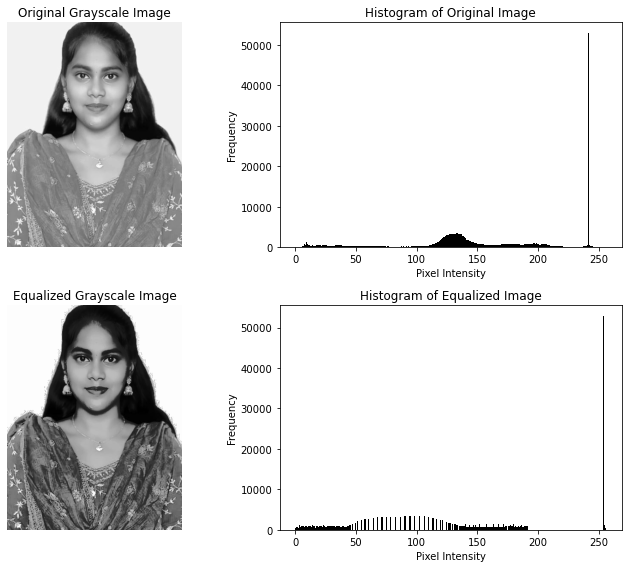

In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

gray_img = cv2.imread(r"C:\Users\sdhan\Downloads\WhatsApp Image 2026-10-17 at 3.09.40 PM.jpeg", cv2.IMREAD_GRAYSCALE)

if gray_img is None:
    print("parrot.jpg not found. Creating a dummy image for demonstration.")
    dummy_img = np.zeros((100, 100), dtype=np.uint8)
    for i in range(100):
        dummy_img[i, :] = i * 2.55  # Create a gradient from 0 to 255
    gray_img = dummy_img

equalized_img = cv2.equalizeHist(gray_img)

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray_img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.hist(gray_img.ravel(), 256, [0, 256], color='black')
plt.title('Histogram of Original Image')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)
plt.imshow(equalized_img, cmap='gray')
plt.title('Equalized Grayscale Image')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.hist(equalized_img.ravel(), 256, [0, 256], color='black')
plt.title('Histogram of Equalized Image')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


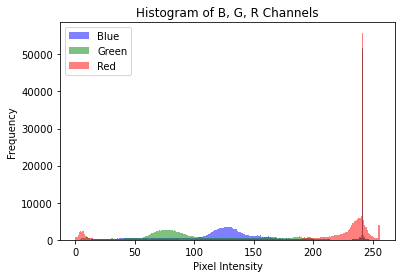

In [5]:
color_img = cv2.imread(r"C:\Users\sdhan\Downloads\WhatsApp Image 2026-10-17 at 3.09.40 PM.jpeg")


if color_img is None:
    print("Error: 'parrot.jpg' could not be loaded for color processing. Creating a dummy color image.")
    dummy_color_img = np.zeros((100, 100, 3), dtype=np.uint8)
    for i in range(100):
        dummy_color_img[i, :, 0] = i * 2.55 # Red channel gradient
        dummy_color_img[i, :, 1] = 255 - (i * 2.55) # Green channel gradient
        dummy_color_img[:, i, 2] = i * 2.55 # Blue channel gradient
    color_img = dummy_color_img

color_img_rgb = cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB)

b, g, r = cv2.split(color_img)

plt.figure(figsize=(6, 4))
plt.hist(b.ravel(), 256, [0, 256], color='blue', alpha=0.5, label='Blue')
plt.hist(g.ravel(), 256, [0, 256], color='green', alpha=0.5, label='Green')
plt.hist(r.ravel(), 256, [0, 256], color='red', alpha=0.5, label='Red')
plt.title('Histogram of B, G, R Channels')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

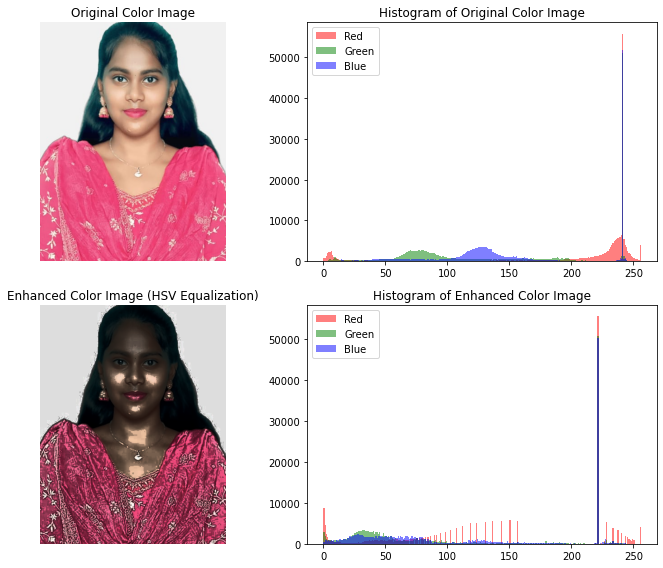

In [6]:
hsv_img = cv2.cvtColor(color_img, cv2.COLOR_BGR2HSV)

h, s, v = cv2.split(hsv_img)

v_equalized = cv2.equalizeHist(v)

hsv_equalized = cv2.merge([h, s, v_equalized])
enhanced_color_img = cv2.cvtColor(hsv_equalized, cv2.COLOR_HSV2BGR)
enhanced_color_img_rgb = cv2.cvtColor(enhanced_color_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(color_img_rgb)
plt.title('Original Color Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.hist(color_img_rgb[:, :, 0].ravel(), 256, [0, 256], color='red', alpha=0.5, label='Red')
plt.hist(color_img_rgb[:, :, 1].ravel(), 256, [0, 256], color='green', alpha=0.5, label='Green')
plt.hist(color_img_rgb[:, :, 2].ravel(), 256, [0, 256], color='blue', alpha=0.5, label='Blue')
plt.title('Histogram of Original Color Image')
plt.legend()

plt.subplot(2, 2, 3)
plt.imshow(enhanced_color_img_rgb)
plt.title('Enhanced Color Image (HSV Equalization)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.hist(enhanced_color_img_rgb[:, :, 0].ravel(), 256, [0, 256], color='red', alpha=0.5, label='Red')
plt.hist(enhanced_color_img_rgb[:, :, 1].ravel(), 256, [0, 256], color='green', alpha=0.5, label='Green')
plt.hist(enhanced_color_img_rgb[:, :, 2].ravel(), 256, [0, 256], color='blue', alpha=0.5, label='Blue')
plt.title('Histogram of Enhanced Color Image')
plt.legend()

plt.tight_layout()
plt.show()